# Notebook 4: 3-Layer GNN Encoder & PPO Actor-Critic Policy Training

### Objectives
1. Inspect the 3-Layer Graph Neural Network encoder architecture and feature dimensions.
2. Perform forward pass through the Molecular Actor-Critic network with action masking.
3. Load trained PPO policy weights (`checkpoints/ppo_adaptive.pt` and `ppo_baseline.pt`).
4. Analyze real training return curves and Delta-QED progression across training episodes.

In [1]:
import torch
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Ensure project root is in sys.path
root_dir = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.path.abspath('.')
if root_dir not in sys.path:
    sys.path.insert(0, root_dir)

from rdkit import Chem
from implementation.graph_utils import mol_to_pyg_data
from implementation.gnn_encoder import MolecularGNNEncoder
from implementation.actor_critic import MolecularActorCritic
from implementation.ppo_agent import PPOAgent
from implementation.environment import MolecularGraphEnv

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch Version: {torch.__version__}, Active Device: {device}')

PyTorch Version: 2.9.1+cu128, Active Device: cuda


### 1. 3-Layer GNN Encoder Architecture & Forward Pass
The GNN processes the molecular graph with 21 node features and 4 bond features.

In [2]:
mol = Chem.MolFromSmiles('CC(=O)Oc1ccccc1C(=O)O') # Aspirin
data = mol_to_pyg_data(mol, current_step=0, max_steps=10, qed=0.55, sas=1.6, sim=1.0, q0=0.55, sas_0=1.6).to(device)
scalars = data.scalars.to(device)

encoder = MolecularGNNEncoder().to(device)
embedding = encoder(data, scalars)
print(f'Number of atoms: {data.x.shape[0]}, Node feature dim: {data.x.shape[1]}')
print(f'Edge index shape: {data.edge_index.shape}, Edge feature dim: {data.edge_attr.shape[1]}')
print(f'Global graph representation shape: {embedding.shape} (Expected: [1, 128])')

Number of atoms: 13, Node feature dim: 21
Edge index shape: torch.Size([2, 26]), Edge feature dim: 4
Global graph representation shape: torch.Size([1, 128]) (Expected: [1, 128])


C:\Users\vuppa\torch-gpu-env\lib\site-packages\torch_geometric\utils\_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


### 2. Molecular Actor-Critic Policy & Value Heads
Evaluates action distribution over the 1,901-action discrete space and predicts state value.

In [3]:
actor_critic = MolecularActorCritic().to(device)
logits, value = actor_critic(data, scalars)
print(f'Actor output logits shape: {logits.shape} (Total actions: 1,901)')
print(f'Critic estimated state value V(s): {value.item():.4f}')

Actor output logits shape: torch.Size([1, 1901]) (Total actions: 1,901)
Critic estimated state value V(s): 0.0511


### 3. Load Trained Model Weights & Inspection
Loads the trained checkpoint from `checkpoints/`.

In [4]:
ckpt_path = os.path.join(root_dir, 'checkpoints', 'ppo_adaptive.pt')
if not os.path.exists(ckpt_path):
    ckpt_path = os.path.join(root_dir, 'cache', 'checkpoints', 'ppo_adaptive.pt')

agent = PPOAgent(device=device)
meta = agent.load_checkpoint(ckpt_path)
print(f'Successfully loaded PPO Adaptive checkpoint! Metadata: {meta}')

Successfully loaded PPO Adaptive checkpoint! Metadata: {'reward_mode': 'adaptive', 'num_episodes': 60}


### 4. Training Learning Curves
Inspect episode returns and Delta-QED progression comparing Baseline vs Adaptive reward shaping.

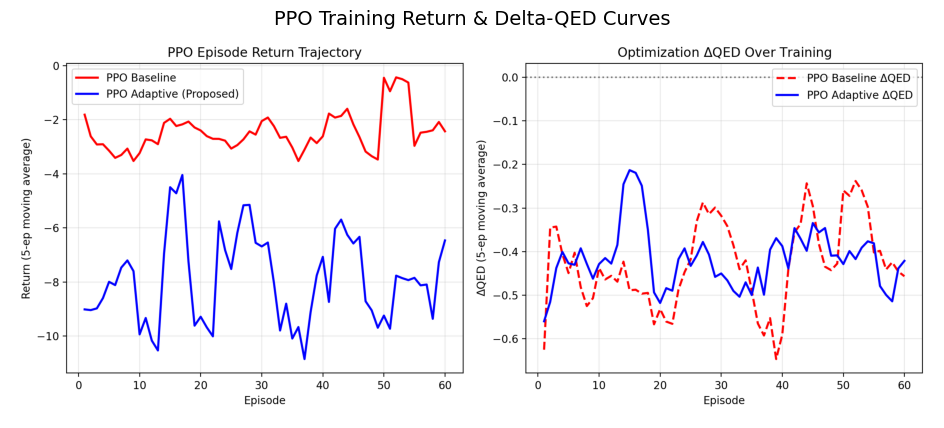

In [5]:
fig_path = os.path.join(root_dir, 'figures', 'training_reward_curves.png')
if os.path.exists(fig_path):
    img = Image.open(fig_path)
    plt.figure(figsize=(12, 5))
    plt.imshow(img)
    plt.axis('off')
    plt.title('PPO Training Return & Delta-QED Curves', fontsize=14)
    plt.show()